# Laboratorium 3 — Dane obrazowe i wideo: potok i własny zbiór

## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision opencv-python-headless matplotlib

## Import bibliotek i wybór urządzenia

In [ ]:
import os, urllib.request
import numpy as np
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| OpenCV:", cv2.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | OpenCV: 4.14.0 | urządzenie: cuda


In [ ]:
!unzip zbior_kwiaty.zip

Archive:  zbior_kwiaty.zip
replace zbior_kwiaty/flower_photos/daisy/100080576_f52e8ee070_n.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

## 1. Własny mini-zbiór (dwie klasy)

Zbiór został pobrany z platformy Kaggle. Zostały z niego wybrane 2 klasy (tulips i daisy) z 5 dostępnych klas, które następnie zostały zmniejszone do 48 obrazów na jedną klasę.  
Link do danych zawiera wszystkie dostępne klasy wraz z załączoną licencją do zdjęć.  
Link: https://www.kaggle.com/datasets/batoolabbas91/flower-photos-by-the-tensorflow-team

In [ ]:
ROOT = "/content/zbior_kwiaty/flower_photos"
classes_demo = ["daisy", "tulips"]

for c in classes_demo:
    print(f"  {c}: {len(os.listdir(ROOT+'/'+c))} obrazów")

  daisy: 48 obrazów
  tulips: 48 obrazów


## 2. Wczytanie zbioru przez ImageFolder


In [ ]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

ds = datasets.ImageFolder(ROOT, transform=eval_tf)
print("Klasy:", ds.classes, "-> indeksy:", ds.class_to_idx)
print("Liczba przykładów:", len(ds))

Klasy: ['daisy', 'tulips'] -> indeksy: {'daisy': 0, 'tulips': 1}
Liczba przykładów: 96


Uzasadnienie użytych augmentacji:
- transforms.RandomHorizontalFlip() - Odbicie poziome obrazu z prawdopodobieństwem 0.5. Zbiór obrazów nie zawiera tekstu, cyfr, czy innych rzeczy, które po odbiciu mogą zupełnie stracić sens. Kwiat po odbiciu poziomym dalej w pełni jest rozpoznawalny.
- transforms.RandomRotation(15) - Obrót o losowy kąt [-15, 15]. Niewielka zmiana kątu może przypominać zmianę ustawienia aparatu, co nie powinno wpływać na rozpoznawalność kwiatów.
- transforms.ColorJitter(brightness=0.2, contrast=0.2) - Losowa zmiana jasności i kontrastu. Nie powinna wpływać na rozpoznawalność klasy, ponieważ kwiaty oprócz koloru różnią się też kształtem i budową.

## 3. Siatka przykładów

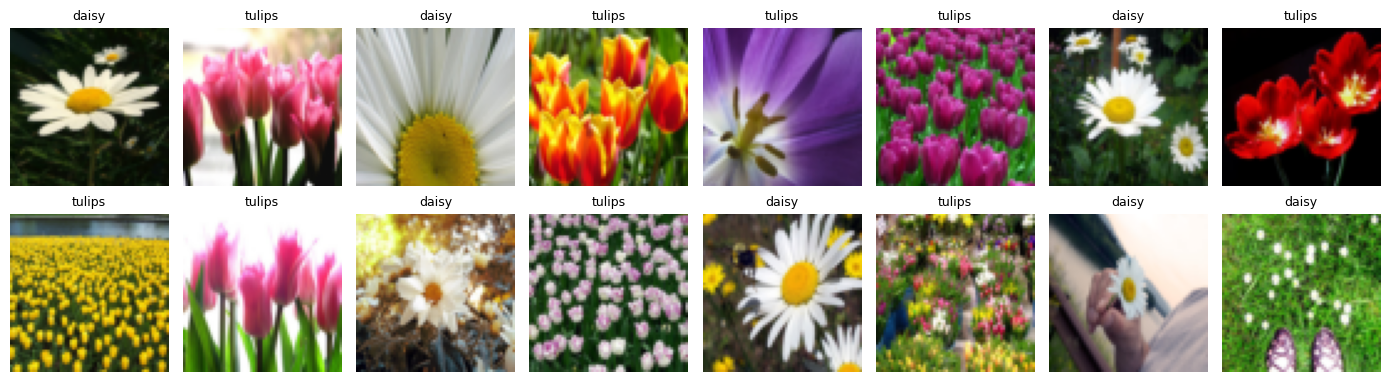

In [ ]:
dl_raw = DataLoader(ds, batch_size=32, shuffle=True)
xb, yb = next(iter(dl_raw))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, label in zip(axes.flat, xb, yb):
    ax.imshow((img * 0.5 + 0.5).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(ds.classes[label.item()], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Podział na trening i walidację

In [ ]:
g = torch.Generator().manual_seed(42) # powtarzalny podział
n = len(datasets.ImageFolder(ROOT))
perm = torch.randperm(n, generator=g).tolist()
n_val = int(0.2 * n)
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), train_idx)
val_ds = Subset(datasets.ImageFolder(ROOT, transform=eval_tf), val_idx)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False)

print(f'Trening: {len(train_ds)}, Walidacja: {len(val_ds)}')

Trening: 77, Walidacja: 19


## 5. Statystyki zbioru

In [ ]:
tabela = pd.DataFrame({
    "Klasa": ds.classes,
    "Cały zbiór": [ds.targets.count(i) for i in range(len(ds.classes))],
    "Trening": [sum(ds.targets[j] == i for j in train_idx) for i in range(len(ds.classes))],
    "Walidacja": [sum(ds.targets[j] == i for j in val_idx) for i in range(len(ds.classes))]
})

display(tabela)

print("Liczba klas:", len(ds.classes))
print("Rozmiar tensora:", ds[0][0].shape)
print("class_to_idx:", ds.class_to_idx)

,Klasa,Cały zbiór,Trening,Walidacja
0,daisy,48,39,9
1,tulips,48,38,10


Liczba klas: 2
Rozmiar tensora: torch.Size([3, 64, 64])
class_to_idx: {'daisy': 0, 'tulips': 1}


## 6. Audyt jednej paczki

In [ ]:
xb, yb = next(iter(train_dl))
print(f'Kształt paczki: {xb.shape}, Typ danych: {xb.dtype}')
print(f'Zakres wartości po normalizacji: {xb.min().item()}, {xb.max().item()}')
print(f'Wymieszanie klas: {yb.tolist()}')
print(f'Ilość przykładów klas w paczce: {Counter(yb.tolist())}')

Kształt paczki: torch.Size([16, 3, 64, 64]), Typ danych: torch.float32
Zakres wartości po normalizacji: -1.0, 1.0
Wymieszanie klas: [1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0]
Ilość przykładów klas w paczce: Counter({0: 9, 1: 7})


## 7. Podgląd augmentacji

Ta sama augmentacja zastosowana wielokrotnie do jednego obrazu daje różne warianty — to zwiększa różnorodność zbioru treningowego.

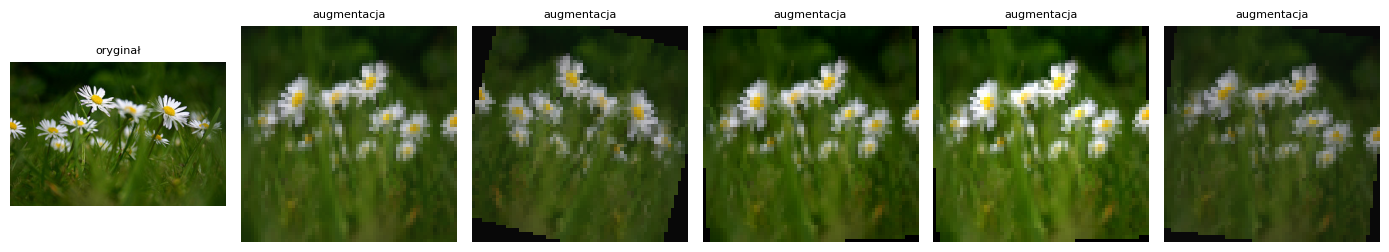

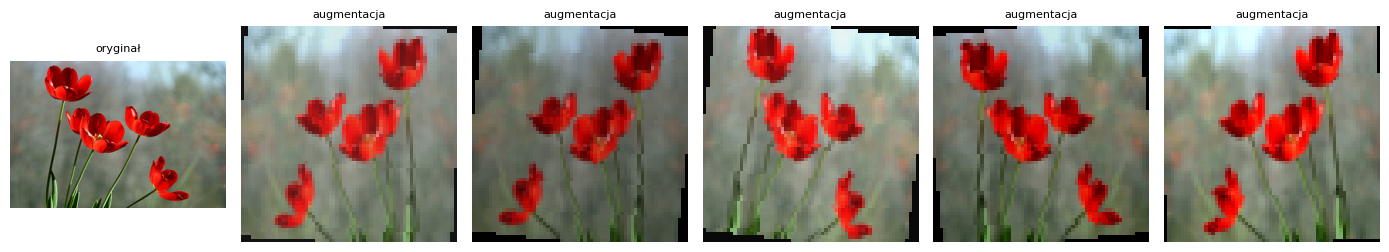

In [ ]:
sample = [2, 80]
for s in sample:
  raw = Image.open(ds.samples[s][0]).convert("RGB")
  fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
  axes[0].imshow(raw); axes[0].set_title("oryginał", fontsize=8); axes[0].axis("off")
  for ax in axes[1:]:
      aug = train_tf(raw)
      ax.imshow((aug*0.5 + 0.5).permute(1, 2, 0).numpy())
      ax.set_title("augmentacja", fontsize=8); ax.axis("off")
  plt.tight_layout(); plt.show()

Użyte augmentacje nie powodują istotnych zniekształceń obrazów. Charakterystyczne cechy, takie jak budowa i kształt kwiatu, pozostają zachowane i nadal pozwalają rozróżnić klasy. Zmiany jasności i kontrastu nie wpływają znacząco na kolorystykę, dzięki czemu obrazy po przekształceniach nadal można prawidłowo przypisać do odpowiednich klas.